# EXPT NO: 9 — TEXT CLASSIFICATION AND TEXT GENERATION USING TRANSFORMERS
**DATE:** `01/11/2026`  
**NAME:** `Jeevanantham K`  **ROLL NO:** `24BAD047`

**Aim:** To implement text classification by fine-tuning a pretrained BERT model (IMDb sentiment) and develop a simple sequence-to-sequence text generation application using T5-small.



## PRE-LAB QUESTIONS
**1. What is a Transformer model in NLP?**  
A neural architecture built on the self-attention mechanism. It processes all tokens of a sequence in parallel and learns how strongly each token relates to every other token, giving context-aware representations. It consists of encoder and/or decoder stacks (multi-head attention, feed-forward layers, residual connections, layer normalisation, positional encodings) and replaced RNN/LSTM models because it trains faster and captures long-range dependencies better.

**2. What is BERT and how is it used for text classification?**  
BERT (Bidirectional Encoder Representations from Transformers) is an encoder-only Transformer pretrained on large corpora with Masked Language Modelling and Next Sentence Prediction, so it reads context in both directions. For classification, the text is tokenized with a `[CLS]` token at the start; the final hidden state of `[CLS]` is passed to a small linear classification layer that outputs class probabilities.

**3. What is fine-tuning?**  
Continuing the training of a pretrained model on a smaller, task-specific labelled dataset (with a small learning rate) so the general language knowledge is adapted to the target task, needing far less data and compute than training from scratch.

**4. Difference between text classification and text generation?**  
Classification maps an input text to one label from a fixed set (e.g., positive/negative). Generation produces a new sequence of text token by token (e.g., a summary or translation); the output is open-ended and variable in length.

**5. What is a sequence-to-sequence model and how is it used in generation?**  
A model with an encoder that converts the input sequence into contextual representations and a decoder that generates the output sequence autoregressively, attending to the encoder output. Examples: T5, BART. Used for summarization, translation, question answering and paraphrasing.

## Setup — install libraries and student details

In [1]:
!pip install -q transformers datasets accelerate scikit-learn

In [2]:
import os, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
warnings.filterwarnings("ignore")


STUDENT_NAME = "Jeevanantham K"
ROLL_NO      = "24BAD047"
DATE         = "01-11-2026"


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Student : {STUDENT_NAME} | Roll No : {ROLL_NO} | Date : {DATE}")
print("Device  :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (training will be slow; switch to GPU)")

Student : Jeevanantham K | Roll No : 24BAD047 | Date : 01-11-2026
Device  : cuda | Tesla T4


---
## PART A: DATASET PREPARATION AND TEXT PREPROCESSING
Dataset: **IMDb Movie Reviews** (binary sentiment: 0 = negative, 1 = positive).

In [3]:
from datasets import load_dataset

print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] PART A - Dataset loading")
dataset = load_dataset("stanfordnlp/imdb")
print(dataset)

label_names = {0: "NEGATIVE", 1: "POSITIVE"}

print("\nNumber of samples -> train:", len(dataset["train"]), "| test:", len(dataset["test"]))

[Roll No: 24BAD047 | Jeevanantham K] PART A - Dataset loading


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Number of samples -> train: 25000 | test: 25000


In [4]:
# Explore sample entries and their labels
for i in [0, 1, 12500, 12501]:
    row = dataset["train"][i]
    print(f"Index {i} | Label = {row['label']} ({label_names[row['label']]})")
    print(row["text"][:300], "...\n")

Index 0 | Label = 0 (NEGATIVE)
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h ...

Index 1 | Label = 0 (NEGATIVE)
"I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity ...

Index 12500 | Label = 1 (POSITIVE)
Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really understand, and whose naivety is all the m

Train distribution:
 label
NEGATIVE    12500
POSITIVE    12500
Name: count, dtype: int64

Test distribution:
 label
NEGATIVE    12500
POSITIVE    12500
Name: count, dtype: int64

Review length (words):
count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: word_count, dtype: float64


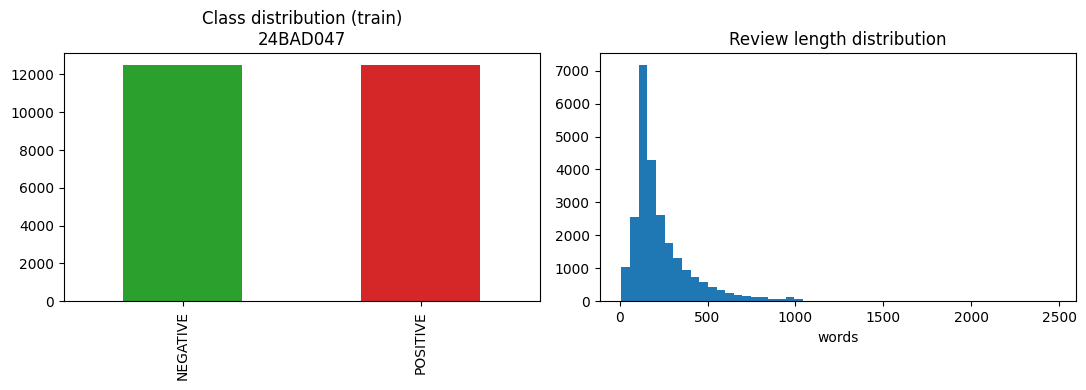

In [5]:
# Class label distribution
train_df = dataset["train"].to_pandas()
test_df  = dataset["test"].to_pandas()

print("Train distribution:\n", train_df["label"].value_counts().rename(label_names))
print("\nTest distribution:\n", test_df["label"].value_counts().rename(label_names))

train_df["word_count"] = train_df["text"].str.split().str.len()
print("\nReview length (words):")
print(train_df["word_count"].describe())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
train_df["label"].map(label_names).value_counts().plot(kind="bar", ax=ax[0], color=["tab:green", "tab:red"])
ax[0].set_title(f"Class distribution (train)\n{ROLL_NO}"); ax[0].set_xlabel("")
ax[1].hist(train_df["word_count"], bins=50, color="tab:blue")
ax[1].set_title("Review length distribution"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.show()

In [6]:
# Use predefined splits; take a balanced random subset for fast training
TRAIN_SIZE, TEST_SIZE = 4000, 1000     # increase for better accuracy (e.g. 25000 / 25000)
train_ds = dataset["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
test_ds  = dataset["test"].shuffle(seed=SEED).select(range(TEST_SIZE))
print("Subset sizes -> train:", len(train_ds), "| test:", len(test_ds))
print("Subset train labels:", pd.Series(train_ds["label"]).value_counts().to_dict())

Subset sizes -> train: 4000 | test: 1000
Subset train labels: {0: 2015, 1: 1985}


In [7]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"
MAX_LEN = 256
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Tokenizer demonstration
sample = "This movie was absolutely fantastic!"
enc = tokenizer(sample)
print("Text      :", sample)
print("Tokens    :", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("Input IDs :", enc["input_ids"])
print("Attention :", enc["attention_mask"])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Text      : This movie was absolutely fantastic!
Tokens    : ['[CLS]', 'this', 'movie', 'was', 'absolutely', 'fantastic', '!', '[SEP]']
Input IDs : [101, 2023, 3185, 2001, 7078, 10392, 999, 102]
Attention : [1, 1, 1, 1, 1, 1, 1, 1]


In [8]:
def tokenize_fn(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=MAX_LEN)

tokenized_train = train_ds.map(tokenize_fn, batched=True)
tokenized_test  = test_ds.map(tokenize_fn, batched=True)

# Convert to PyTorch format (Trainer expects the column name 'labels')
tokenized_train = tokenized_train.rename_column("label", "labels").remove_columns(["text"])
tokenized_test  = tokenized_test.rename_column("label", "labels").remove_columns(["text"])
tokenized_train.set_format("torch")
tokenized_test.set_format("torch")

print(f"[Roll No: {ROLL_NO}] Tokenized columns:", tokenized_train.column_names)
print("Example shapes:", {k: tuple(v.shape) for k, v in tokenized_train[0].items()})

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

[Roll No: 24BAD047] Tokenized columns: ['labels', 'input_ids', 'token_type_ids', 'attention_mask']
Example shapes: {'labels': (), 'input_ids': (256,), 'token_type_ids': (256,), 'attention_mask': (256,)}


In [9]:
# Batch-wise processing with DataLoader
from torch.utils.data import DataLoader

loader = DataLoader(tokenized_train, batch_size=16, shuffle=True)
batch = next(iter(loader))
print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] One batch:")
for k, v in batch.items():
    print(f"  {k:15s} shape = {tuple(v.shape)}")

[Roll No: 24BAD047 | Jeevanantham K] One batch:
  labels          shape = (16,)
  input_ids       shape = (16, 256)
  token_type_ids  shape = (16, 256)
  attention_mask  shape = (16, 256)


---
## PART B: FINE-TUNING BERT FOR TEXT CLASSIFICATION

In [10]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] PART B - Model loading")
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {"NEGATIVE": 0, "POSITIVE": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
print("Trainable parameters: {:,}".format(sum(p.numel() for p in model.parameters() if p.requires_grad)))

[Roll No: 24BAD047 | Jeevanantham K] PART B - Model loading


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 109,483,778


In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    return {"accuracy": accuracy_score(labels, preds), "precision": precision, "recall": recall, "f1": f1}

# Training parameters
LEARNING_RATE = 2e-5
BATCH_SIZE    = 16
EPOCHS        = 2

training_args = TrainingArguments(
    output_dir="./bert_imdb_results",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics,
)
print(f"Learning rate={LEARNING_RATE}, batch size={BATCH_SIZE}, epochs={EPOCHS}")

Learning rate=2e-05, batch size=16, epochs=2


In [12]:
print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] Fine-tuning started...")
t0 = time.time()
train_output = trainer.train()
print(f"Training finished in {(time.time()-t0)/60:.1f} min | final training loss = {train_output.training_loss:.4f}")

[Roll No: 24BAD047 | Jeevanantham K] Fine-tuning started...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.368495,0.272240,0.888000,0.880567,0.891393,0.885947
2,0.194983,0.292159,0.895000,0.882236,0.905738,0.893832


Training finished in 1.8 min | final training loss = 0.2848


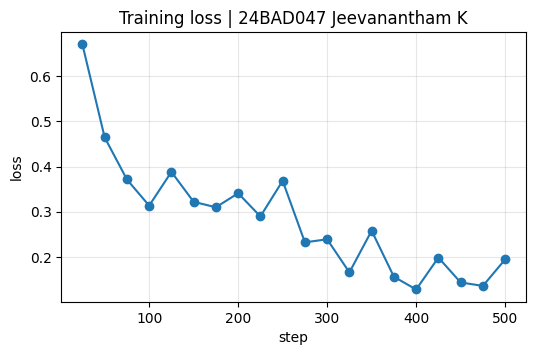

In [13]:
# Training loss curve
logs = pd.DataFrame(trainer.state.log_history)
loss_logs = logs.dropna(subset=["loss"])
plt.figure(figsize=(6, 3.5))
plt.plot(loss_logs["step"], loss_logs["loss"], marker="o")
plt.title(f"Training loss | {ROLL_NO} {STUDENT_NAME}")
plt.xlabel("step"); plt.ylabel("loss"); plt.grid(alpha=.3); plt.show()

[Roll No: 24BAD047 | Jeevanantham K] Evaluation on test set


Accuracy : 0.8950
Precision: 0.8822
Recall   : 0.9057
F1-score : 0.8938

              precision    recall  f1-score   support

    NEGATIVE       0.91      0.88      0.90       512
    POSITIVE       0.88      0.91      0.89       488

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.89      1000
weighted avg       0.90      0.90      0.90      1000



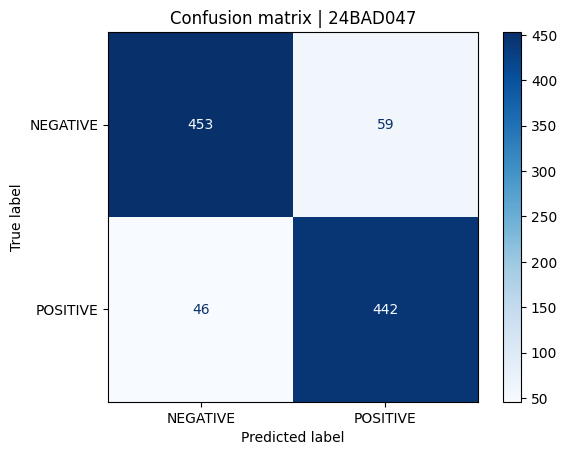

In [14]:
# Evaluation on the test set
print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] Evaluation on test set")
pred_output = trainer.predict(tokenized_test)
y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=-1)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary")
print(f"Accuracy : {acc:.4f}\nPrecision: {prec:.4f}\nRecall   : {rec:.4f}\nF1-score : {f1:.4f}\n")
print(classification_report(y_true, y_pred, target_names=["NEGATIVE", "POSITIVE"]))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["NEGATIVE", "POSITIVE"]).plot(cmap="Blues")
plt.title(f"Confusion matrix | {ROLL_NO}"); plt.show()

In [15]:
# Testing the model with new text inputs
def predict_sentiment(texts):
    model.eval()
    enc = tokenizer(texts, padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits, dim=-1).cpu().numpy()
    return [(id2label[int(p.argmax())], float(p.max())) for p in probs]

new_texts = [
    "An outstanding film with brilliant acting and a gripping storyline.",
    "I loved every minute of it. Highly recommended!",
    "The plot was boring, the acting was terrible and I wasted my time.",
    "Worst movie I have seen this year. Absolutely awful.",
    "It was okay, some parts were good but the ending was disappointing.",
]
print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] Predictions on new text")
for t, (lab, conf) in zip(new_texts, predict_sentiment(new_texts)):
    print(f"{lab:8s} ({conf:.2%}) <- {t}")

[Roll No: 24BAD047 | Jeevanantham K] Predictions on new text
POSITIVE (98.21%) <- An outstanding film with brilliant acting and a gripping storyline.
POSITIVE (98.44%) <- I loved every minute of it. Highly recommended!
NEGATIVE (98.46%) <- The plot was boring, the acting was terrible and I wasted my time.
NEGATIVE (98.17%) <- Worst movie I have seen this year. Absolutely awful.
NEGATIVE (98.10%) <- It was okay, some parts were good but the ending was disappointing.


In [16]:
# Save fine-tuned model and tokenizer
SAVE_DIR = "./bert_imdb_finetuned"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print(f"[Roll No: {ROLL_NO}] Saved to {SAVE_DIR}:", os.listdir(SAVE_DIR))

# Reload test (verifies the saved model works)
reloaded = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to(device).eval()
re_tok = AutoTokenizer.from_pretrained(SAVE_DIR)
enc = re_tok("A wonderful, touching movie.", return_tensors="pt").to(device)
print("Reloaded model prediction:", reloaded.config.id2label[int(reloaded(**enc).logits.argmax(-1))])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[Roll No: 24BAD047] Saved to ./bert_imdb_finetuned: ['model.safetensors', 'config.json', 'training_args.bin', 'tokenizer.json', 'tokenizer_config.json']


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Reloaded model prediction: POSITIVE


---
## PART C: SEQUENCE-TO-SEQUENCE APPLICATION USING TRANSFORMERS (T5-small)
Task: **text summarization** (prefix `summarize:`). T5 is a text-to-text model, so the same model also handles translation (e.g., `translate English to German:`), shown at the end.

In [17]:
from transformers import AutoModelForSeq2SeqLM

print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] PART C - Loading T5-small")
t5_name = "google-t5/t5-small"
t5_tokenizer = AutoTokenizer.from_pretrained(t5_name)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(t5_name).to(device).eval()
print("T5 parameters: {:,}".format(sum(p.numel() for p in t5_model.parameters())))

[Roll No: 24BAD047 | Jeevanantham K] PART C - Loading T5-small


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5 parameters: 60,506,624


In [18]:
def t5_generate(text, prefix="summarize: ", max_new_tokens=60, min_new_tokens=10, num_beams=4,
                do_sample=False, temperature=1.0, top_p=1.0, no_repeat_ngram_size=3, length_penalty=1.0):
    inputs = t5_tokenizer(prefix + text, return_tensors="pt", max_length=512, truncation=True).to(device)
    kwargs = dict(max_new_tokens=max_new_tokens, min_new_tokens=min_new_tokens,
                  no_repeat_ngram_size=no_repeat_ngram_size, early_stopping=True)
    if do_sample:
        kwargs.update(do_sample=True, temperature=temperature, top_p=top_p, num_beams=1)
    else:
        kwargs.update(num_beams=num_beams, length_penalty=length_penalty)
    with torch.no_grad():
        out = t5_model.generate(**inputs, **kwargs)
    return t5_tokenizer.decode(out[0], skip_special_tokens=True)

article_1 = (
    "Artificial intelligence is transforming healthcare by enabling faster and more accurate diagnosis. "
    "Machine learning models can analyse medical images such as X-rays and MRI scans to detect diseases like "
    "cancer at early stages. Hospitals are also using AI to predict patient admissions, optimise staff schedules "
    "and reduce waiting times. However, experts warn that issues such as data privacy, algorithmic bias and a "
    "lack of transparency must be addressed before AI can be widely trusted in clinical practice."
)
article_2 = (
    "The Indian Space Research Organisation launched a new earth observation satellite from Sriharikota on "
    "Sunday. The satellite carries high resolution cameras that will help monitor agriculture, forests and "
    "water resources across the country. Scientists said the mission will also support disaster management by "
    "providing timely images of floods and cyclones. The launch vehicle placed the satellite into its intended "
    "orbit about eighteen minutes after lift-off."
)
article_3 = (
    "Regular exercise has many benefits for both the body and the mind. Studies show that thirty minutes of "
    "moderate activity each day lowers the risk of heart disease, improves sleep and reduces symptoms of anxiety "
    "and depression. Experts recommend combining aerobic exercise, strength training and stretching for the best "
    "results, and suggest that beginners start slowly and increase intensity gradually."
)
articles = {"Healthcare AI": article_1, "ISRO satellite": article_2, "Exercise": article_3}

print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] T5 summarization (beam search, 4 beams)\n")
for name, txt in articles.items():
    print(f"INPUT [{name}] ({len(txt.split())} words):\n{txt}\n")
    print("OUTPUT:", t5_generate(txt), "\n" + "-"*90)

[Roll No: 24BAD047 | Jeevanantham K] T5 summarization (beam search, 4 beams)

INPUT [Healthcare AI] (77 words):
Artificial intelligence is transforming healthcare by enabling faster and more accurate diagnosis. Machine learning models can analyse medical images such as X-rays and MRI scans to detect diseases like cancer at early stages. Hospitals are also using AI to predict patient admissions, optimise staff schedules and reduce waiting times. However, experts warn that issues such as data privacy, algorithmic bias and a lack of transparency must be addressed before AI can be widely trusted in clinical practice.

OUTPUT: machine learning models can analyse medical images such as X-rays and MRI scans to detect diseases like cancer at early stages. hospitals are also using AI to predict patient admissions, optimise staff schedules and reduce waiting times. experts warn issues such as data privacy, algorithmic 
-----------------------------------------------------------------------------

In [19]:
# Experiment with generation parameters on article_1
print(f"[Roll No: {ROLL_NO}] Effect of generation parameters\n")
settings = {
    "Greedy (beams=1), max 30":      dict(num_beams=1, max_new_tokens=30),
    "Beam=4, max 30":                dict(num_beams=4, max_new_tokens=30),
    "Beam=4, max 60":                dict(num_beams=4, max_new_tokens=60),
    "Beam=4, max 100, min 40":       dict(num_beams=4, max_new_tokens=100, min_new_tokens=40),
    "Beam=8, max 60":                dict(num_beams=8, max_new_tokens=60),
    "Sampling T=0.7, top_p=0.9":     dict(do_sample=True, temperature=0.7, top_p=0.9, max_new_tokens=60),
    "Sampling T=1.5, top_p=1.0":     dict(do_sample=True, temperature=1.5, top_p=1.0, max_new_tokens=60),
}
torch.manual_seed(SEED)
exp_rows = []
for name, kw in settings.items():
    out = t5_generate(article_1, **kw)
    exp_rows.append({"Setting": name, "Output": out, "Words": len(out.split())})
    print(f"[{name}] ({len(out.split())} words)\n  {out}\n")
exp_df = pd.DataFrame(exp_rows)

[transformers] The following generation flags are not valid and may be ignored: ['early_stopping']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[Roll No: 24BAD047] Effect of generation parameters

[Greedy (beams=1), max 30] (25 words)
  artificial intelligence can analyse medical images to detect diseases like cancer. hospitals also using AI to predict patient admissions, optimise staff schedules and reduce waiting

[Beam=4, max 30] (22 words)
  machine learning models can analyse medical images such as X-rays and MRI scans to detect diseases like cancer at early stages. hospitals

[Beam=4, max 60] (45 words)
  machine learning models can analyse medical images such as X-rays and MRI scans to detect diseases like cancer at early stages. hospitals are also using AI to predict patient admissions, optimise staff schedules and reduce waiting times. experts warn issues such as data privacy, algorithmic

[Beam=4, max 100, min 40] (62 words)
  machine learning models can analyse medical images such as X-rays and MRI scans to detect diseases like cancer at early stages. hospitals are also using AI to predict patient admissions, optimi

In [20]:
# Other tasks with the same model: translation and different inputs
tasks = [
    ("translate English to German: ", "The weather is very nice today and we are going to the park."),
    ("translate English to French: ", "I would like to book a table for two people this evening."),
    ("summarize: ", "Transformers use self attention to model relationships between all words in a sentence. "
                    "This allows them to capture long range dependencies and to be trained in parallel, which "
                    "makes them much faster to train than recurrent networks on large datasets."),
]
print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] Other T5 tasks\n")
task_rows = []
for prefix, txt in tasks:
    out = t5_generate(txt, prefix=prefix, max_new_tokens=60, min_new_tokens=1)
    task_rows.append({"Task": prefix.strip(), "Input": txt, "Output": out})
    print(f"{prefix}\n  IN : {txt}\n  OUT: {out}\n")

[Roll No: 24BAD047 | Jeevanantham K] Other T5 tasks

translate English to German: 
  IN : The weather is very nice today and we are going to the park.
  OUT: Das Wetter ist heute sehr schön und wir gehen zum Park.

translate English to French: 
  IN : I would like to book a table for two people this evening.
  OUT: Je voudrais réserver une table pour deux personnes ce soir.

summarize: 
  IN : Transformers use self attention to model relationships between all words in a sentence. This allows them to capture long range dependencies and to be trained in parallel, which makes them much faster to train than recurrent networks on large datasets.
  OUT: Transformers use self attention to model relationships between words in a sentence. this allows them to capture long range dependencies and to be trained in parallel.



In [21]:
# Save generated outputs for further analysis
rows = []
for name, txt in articles.items():
    rows.append({"Roll_No": ROLL_NO, "Task": "summarize", "Input_Name": name, "Setting": "beam=4,max=60",
                 "Input": txt, "Output": t5_generate(txt)})
for r in exp_rows:
    rows.append({"Roll_No": ROLL_NO, "Task": "summarize", "Input_Name": "Healthcare AI", "Setting": r["Setting"],
                 "Input": article_1, "Output": r["Output"]})
for r in task_rows:
    rows.append({"Roll_No": ROLL_NO, "Task": r["Task"], "Input_Name": "-", "Setting": "beam=4",
                 "Input": r["Input"], "Output": r["Output"]})
out_df = pd.DataFrame(rows)
out_df.to_csv("t5_generated_outputs.csv", index=False)
print(f"Saved {len(out_df)} generated outputs to t5_generated_outputs.csv")
out_df[["Task", "Setting", "Output"]].head(10)

Saved 13 generated outputs to t5_generated_outputs.csv


,Task,Setting,Output
0,summarize,"beam=4,max=60",machine learning models can analyse medical im...
1,summarize,"beam=4,max=60",the satellite carries high resolution cameras ...
2,summarize,"beam=4,max=60",thirty minutes of moderate activity each day l...
3,summarize,"Greedy (beams=1), max 30",artificial intelligence can analyse medical im...
4,summarize,"Beam=4, max 30",machine learning models can analyse medical im...
5,summarize,"Beam=4, max 60",machine learning models can analyse medical im...
6,summarize,"Beam=4, max 100, min 40",machine learning models can analyse medical im...
7,summarize,"Beam=8, max 60",machine learning models can analyse medical im...
8,summarize,"Sampling T=0.7, top_p=0.9",AI can analyse medical images such as X-rays a...
9,summarize,"Sampling T=1.5, top_p=1.0",artificial intelligence can improve healthcare...


---
## PART D: MODEL TESTING AND OUTPUT ANALYSIS

In [22]:
# D1. Test fine-tuned BERT with positive and negative inputs
test_inputs = {
    "POSITIVE": [
        "A masterpiece! The direction, music and performances were superb.",
        "Heartwarming and funny, I would happily watch it again.",
        "Great story and an amazing cast. One of the best films of the decade.",
        "Not bad at all, I was pleasantly surprised by how good it was.",       # mild negation
    ],
    "NEGATIVE": [
        "Dull, predictable and far too long. A complete waste of money.",
        "The dialogue was cringe-worthy and the acting was wooden.",
        "I walked out halfway through. Terrible script and poor editing.",
        "This movie is not good; I expected so much more.",                      # negation
    ],
}
rows = []
print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] PART D - BERT predictions")
for true_lab, texts in test_inputs.items():
    for t, (pred, conf) in zip(texts, predict_sentiment(texts)):
        rows.append({"Text": t, "Expected": true_lab, "Predicted": pred, "Confidence": round(conf, 4),
                     "Correct": true_lab == pred})
bert_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80)
display(bert_df)
print(f"\nManual-test accuracy: {bert_df['Correct'].mean():.2%} ({bert_df['Correct'].sum()}/{len(bert_df)})")

[Roll No: 24BAD047 | Jeevanantham K] PART D - BERT predictions


,Text,Expected,Predicted,Confidence,Correct
0,"A masterpiece! The direction, music and performances were superb.",POSITIVE,POSITIVE,0.9850,True
1,"Heartwarming and funny, I would happily watch it again.",POSITIVE,POSITIVE,0.9672,True
2,Great story and an amazing cast. One of the best films of the decade.,POSITIVE,POSITIVE,0.9852,True
3,"Not bad at all, I was pleasantly surprised by how good it was.",POSITIVE,POSITIVE,0.6700,True
4,"Dull, predictable and far too long. A complete waste of money.",NEGATIVE,NEGATIVE,0.9493,True
5,The dialogue was cringe-worthy and the acting was wooden.,NEGATIVE,NEGATIVE,0.9904,True
6,I walked out halfway through. Terrible script and poor editing.,NEGATIVE,NEGATIVE,0.9690,True
7,This movie is not good; I expected so much more.,NEGATIVE,NEGATIVE,0.9596,True



Manual-test accuracy: 100.00% (8/8)


[Roll No: 24BAD047] Evaluation metrics


,Accuracy,Precision,Recall,F1-score
BERT (fine-tuned),0.895,0.8822,0.9057,0.8938


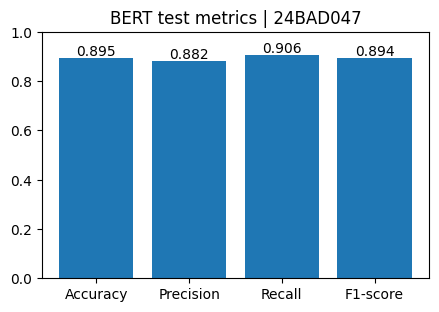

Misclassified: 105 of 1000

True=NEGATIVE | Pred=POSITIVE
Coming from Kiarostami, this art-house visual and sound exposition is a surprise. For a director known for his narratives and keen observation of humans, especially children, this excursion into minimalist cinematography begs for questions: Why did he do it? Was it to keep him busy during a vacation...

True=NEGATIVE | Pred=POSITIVE
"An astronaut (Michael Emmet) dies while returning from a mission and his body is recovered by the military. The base where the dead astronaut is taken to becomes the scene of a bizarre invasion plan from outer space. Alien embryos inside the dead astronaut resurrect the corpse and begin a terrifyin...

True=NEGATIVE | Pred=POSITIVE
I used to always love the bill because of its great script and characters, but lately i feel as though it has turned into an emotional type of soap. If you look at promotional pictures/posters of the bill now you will see either two of the officers hugging/kissing or some

In [23]:
# D2. Metrics summary and error analysis on the test set
metrics = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}
print(f"[Roll No: {ROLL_NO}] Evaluation metrics")
display(pd.DataFrame(metrics, index=["BERT (fine-tuned)"]).round(4))

plt.figure(figsize=(5, 3.2))
plt.bar(metrics.keys(), metrics.values(), color="tab:blue")
plt.ylim(0, 1); plt.title(f"BERT test metrics | {ROLL_NO}")
for i, v in enumerate(metrics.values()): plt.text(i, v + .01, f"{v:.3f}", ha="center")
plt.show()

# Misclassified examples
test_texts = test_ds["text"]
wrong_idx = np.where(y_true != y_pred)[0]
print(f"Misclassified: {len(wrong_idx)} of {len(y_true)}")
for i in wrong_idx[:5]:
    print(f"\nTrue={id2label[int(y_true[i])]} | Pred={id2label[int(y_pred[i])]}\n{test_texts[i][:300]}...")

In [24]:
# D3. Compare T5 outputs: relevance, readability, coherence
def overlap_ratio(src, out):
    s, o = set(src.lower().split()), out.lower().split()
    return sum(w in s for w in o) / max(len(o), 1)

rows = []
for name, txt in articles.items():
    out = t5_generate(txt)
    rows.append({"Input": name, "Input words": len(txt.split()), "Output words": len(out.split()),
                 "Compression": round(len(out.split()) / len(txt.split()), 2),
                 "Word overlap w/ source": round(overlap_ratio(txt, out), 2), "Output": out})
cmp_df = pd.DataFrame(rows)
print(f"[Roll No: {ROLL_NO} | {STUDENT_NAME}] T5 output analysis")
display(cmp_df)

print("Effect of generation settings (article_1):")
display(exp_df[["Setting", "Words", "Output"]])

[Roll No: 24BAD047 | Jeevanantham K] T5 output analysis


,Input,Input words,Output words,Compression,Word overlap w/ source,Output
0,Healthcare AI,77,45,0.58,1.00,machine learning models can analyse medical images such as X-rays and MRI sc...
1,ISRO satellite,65,32,0.49,1.00,"the satellite carries high resolution cameras that will monitor agriculture,..."
2,Exercise,60,26,0.43,0.92,thirty minutes of moderate activity each day lowers the risk of heart diseas...


Effect of generation settings (article_1):


,Setting,Words,Output
0,"Greedy (beams=1), max 30",25,artificial intelligence can analyse medical images to detect diseases like c...
1,"Beam=4, max 30",22,machine learning models can analyse medical images such as X-rays and MRI sc...
2,"Beam=4, max 60",45,machine learning models can analyse medical images such as X-rays and MRI sc...
3,"Beam=4, max 100, min 40",62,machine learning models can analyse medical images such as X-rays and MRI sc...
4,"Beam=8, max 60",45,machine learning models can analyse medical images such as X-rays and MRI sc...
5,"Sampling T=0.7, top_p=0.9",26,AI can analyse medical images such as X-rays and MRI scans. hospitals also u...
6,"Sampling T=1.5, top_p=1.0",50,artificial intelligence can improve healthcare by offering quicker diagnosti...


In [25]:
# D4. Comparison table: BERT classification vs. seq2seq generation
comparison = pd.DataFrame({
    "Aspect": ["Architecture", "Pretraining objective", "Output", "Task type", "Typical use cases",
               "Evaluation", "Main limitations"],
    "BERT classifier": ["Encoder-only", "Masked LM + Next Sentence Prediction", "One label from a fixed set + probability",
                        "Discriminative / understanding", "Sentiment, spam, topic, intent detection",
                        "Accuracy, precision, recall, F1", "Max 512 tokens; struggles with sarcasm/negation; fixed classes"],
    "T5 seq2seq": ["Encoder-decoder", "Span corruption (text-to-text)", "Free-form text of variable length",
                   "Generative", "Summarization, translation, QA, paraphrasing",
                   "ROUGE, BLEU, human judgement", "Can be repetitive/generic or hallucinate; t5-small has limited quality; output depends on decoding settings"],
})
display(comparison)

,Aspect,BERT classifier,T5 seq2seq
0,Architecture,Encoder-only,Encoder-decoder
1,Pretraining objective,Masked LM + Next Sentence Prediction,Span corruption (text-to-text)
2,Output,One label from a fixed set + probability,Free-form text of variable length
3,Task type,Discriminative / understanding,Generative
4,Typical use cases,"Sentiment, spam, topic, intent detection","Summarization, translation, QA, paraphrasing"
5,Evaluation,"Accuracy, precision, recall, F1","ROUGE, BLEU, human judgement"
6,Main limitations,Max 512 tokens; struggles with sarcasm/negation; fixed classes,Can be repetitive/generic or hallucinate; t5-small has limited quality; outp...


---
## POST-LAB QUESTIONS
**1. Role of BERT in text classification?**  
BERT acts as a pretrained encoder that converts text into contextual embeddings; the `[CLS]` representation passes through a classification head that predicts the class.

**2. Why is tokenization required?**  
Transformers work on numbers, not raw text. The tokenizer splits text into sub-word tokens (WordPiece for BERT), maps them to integer IDs, adds special tokens, and produces attention masks, with padding/truncation for uniform length.

**3. Purpose of fine-tuning a pretrained BERT model?**  
To adapt BERT's general language knowledge to a specific task/dataset with less data, time and compute, usually giving higher accuracy than training from scratch.

**4. Two evaluation metrics for text classification?**  
Accuracy and F1-score (also precision and recall).

**5. Role of encoder and decoder in a seq2seq Transformer?**  
The encoder reads the entire input and builds contextual representations. The decoder generates the output tokens one at a time, using masked self-attention over previously generated tokens and cross-attention over the encoder output.

**6. Difference between text classification and text generation?**  
Classification assigns one label from a fixed set to a given text; generation produces new, variable-length text sequence token by token.

**7. How does maximum output length affect generation?**  
It caps the number of generated tokens. Too small → truncated, incomplete output; too large → longer output with possible repetition, irrelevant content and higher compute time.

**8. Real-world applications**  
- Transformer-based text classification: sentiment analysis of customer reviews / spam email detection.  
- Text generation: automatic news or document summarization / machine translation / chatbots.

## Result
A pretrained BERT model was fine-tuned for IMDb sentiment classification and evaluated with accuracy, precision, recall and F1-score; a T5-small sequence-to-sequence model was used to generate summaries and translations, and the effect of input and decoding parameters on output quality was analysed.

In [26]:
# Optional: download the saved files (Colab only)
# !zip -qr bert_imdb_finetuned.zip bert_imdb_finetuned
# from google.colab import files
# files.download("bert_imdb_finetuned.zip"); files.download("t5_generated_outputs.csv")
print("Done ->", STUDENT_NAME, ROLL_NO, DATE)

Done -> Jeevanantham K 24BAD047 01-11-2026
